# 07MIAR — Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*

**Actividad:** Comparación de estrategias para la clasificación de imágenes

**Autor(es):** Adelso Steve Araya Solórzano - Fabio Antonio Rodriguez Quesada - Bhuvana Cheemala

**Dataset:** Sign Language MNIST   https://www.kaggle.com/datasets/datamunge/sign-language-mnist

**Problema de clasificación**

## Índice

1. Planteamiento del problema y selección del dataset
2. Carga de datos
3. Inspección y análisis exploratorio
4. Acondicionamiento y preprocesamiento
5. Estrategia 1 — CNN desde cero (*from scratch*)
6. Estrategia 2 — Modelos preentrenados (*transfer learning* y *fine-tuning*)
7. Evaluación y comparación global
8. Conclusiones
9. Referencias y exportación a PDF

**Requisito central:** comparar una CNN entrenada desde cero con, al menos, dos arquitecturas preentrenadas sobre ImageNet. Justificar experimentalmente las decisiones y evaluar finalmente sobre datos no utilizados durante el entrenamiento.

# 1. Planteamiento del problema y selección del dataset

## 1.1 Descripción del problema

**Problema de clasificación:** El problema que se presenta es la identificacion de 24 clases en el lenguaje de señas Americano.

**Aplicación o motivación:** La clasificación de imágenes mediante técnicas de Deep Learning representa una herramienta de gran potencial para automatizar tareas de reconocimiento y análisis visual. La motivación de este proyecto es explorar cómo diferentes arquitecturas de redes neuronales pueden aprender a identificar patrones y clasificar imágenes, comparando el rendimiento de modelos construidos desde cero con modelos preentrenados mediante Transfer Learning. Con ello, se busca comprender las ventajas y limitaciones de cada enfoque, así como evaluar cómo influyen las distintas técnicas de entrenamiento y optimización en la precisión y capacidad de generalización de los modelos.

**Variable objetivo y significado de las clases:** Cada clase identifica un simbolo en lenguaje de señas Americano, en el dataset no se encuentran ni la **"J"** ni la **"Z"** porque estas incluyen movimiento para generar la seña y al ser este un set de fotografias no es posible el movimiento. 

![image info](./dataset/amer_sign2.png)

## 1.2 Dataset seleccionado

- Nombre: Sign Language MNIST
- Fuente y enlace: (https://www.kaggle.com/datasets/datamunge/sign-language-mnist)
- Estructura de directorios y etiquetas: **TEST:** Dataset/sign_mnist_test/sign_mnist_test.csv  **TRAINING:** Dataset/sign_mnist_train/sign_mnist_train.csv
- Número total de imágenes: 34627 (training data 27455) (test data 7172)
- Número de clases: 24 clases
- Dimensiones y formatos de imagen: 28x28 en escala de grises con valores de 0-255

## 1.3 Justificación de la elección

[COMPLETAR: explicar por qué el dataset es adecuado para clasificación y para comparar ambas estrategias.]

In [62]:
# 1.4 Configuración inicial e importaciones
# COMPLETAR: importar las bibliotecas que se utilizarán.
# COMPLETAR: establecer semillas aleatorias para favorecer la reproducibilidad.
# COMPLETAR: definir parámetros generales (rutas, tamaño de imagen, batch size, etc.).

# pip install kagglehub
import pandas as pd

df = pd.read_csv('./Dataset/sign_mnist_train/sign_mnist_train.csv', header=None)
print(df.head())


     0       1       2       3       4       5       6       7       8    \
0  label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8   
1      3     107     118     127     134     139     143     146     150   
2      6     155     157     156     156     156     157     156     158   
3      2     187     188     188     187     187     186     187     188   
4      2     211     211     212     212     211     210     211     210   

      9    ...       775       776       777       778       779       780  \
0  pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780   
1     153  ...       207       207       207       207       206       206   
2     158  ...        69       149       128        87        94       163   
3     187  ...       202       201       200       199       198       199   
4     210  ...       235       234       233       231       230       226   

        781       782       783       784  
0  pixel781  pixel782  pixel78

C:\Users\Fantr\AppData\Local\Temp\ipykernel_15128\132563847.py:9: DtypeWarning: Columns (0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 25: 25, 26: 26, 27: 27, 28: 28, 29: 29, 30: 30, 31: 31, 32: 32, 33: 33, 34: 34, 35: 35, 36: 36, 37: 37, 38: 38, 39: 39, 40: 40, 41: 41, 42: 42, 43: 43, 44: 44, 45: 45, 46: 46, 47: 47, 48: 48, 49: 49, 50: 50, 51: 51, 52: 52, 53: 53, 54: 54, 55: 55, 56: 56, 57: 57, 58: 58, 59: 59, 60: 60, 61: 61, 62: 62, 63: 63, 64: 64, 65: 65, 66: 66, 67: 67, 68: 68, 69: 69, 70: 70, 71: 71, 72: 72, 73: 73, 74: 74, 75: 75, 76: 76, 77: 77, 78: 78, 79: 79, 80: 80, 81: 81, 82: 82, 83: 83, 84: 84, 85: 85, 86: 86, 87: 87, 88: 88, 89: 89, 90: 90, 91: 91, 92: 92, 93: 93, 94: 94, 95: 95, 96: 96, 97: 97, 98: 98, 99: 99, 100: 100, 101: 101, 102: 102, 103: 103, 104: 104, 105: 105, 106: 106, 107: 107, 108: 108, 109: 109, 110: 110, 111: 111, 112: 112, 1

# 2. Carga del conjunto de datos

## 2.1 Descarga y preparación inicial

El dataset esta disponible en Kaggle para descarga mediante el siguiente link https://www.kaggle.com/datasets/datamunge/sign-language-mnist.

## 2.2 Organización de los datos

[COMPLETAR: describir la estructura de carpetas, ficheros y etiquetas. Explicar cómo se identificarán entrenamiento, validación y test.]
El dataset esta organizado en una carpeta llamada "Dataset" que contiene un subdirectorio llamado "sign_mnist_train" y "sign_mnist_test". En este subdirectorio se encuentran los archivos CSV con las etiquetas correspondientes a cada imagen. La primera columna es el label/etiqueta de la imagen, mientras que el resto de columnas son los valores pixeles de la imagen para un total de 28x28 pixeles o 784 en total.

El dataset se divide en dos partes principales: entrenamiento y test. En este caso, se utiliza un 80% para el entrenamiento y un 20% para el test. Se guardan las variables en X_train, X_test, y_test y y_train, respectivamente.

In [ ]:
# COMPLETAR: definir rutas y descargar/preparar el dataset.
# COMPLETAR: implementar, si resulta conveniente, una función reutilizable
# para automatizar la descarga y preparación inicial.
# COMPLETAR: comprobar que las rutas y los ficheros esperados existen.

import random
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el CSV con Pandas
datos_test = './Dataset/sign_mnist_test/sign_mnist_test.csv'
df = pd.read_csv(datos_test)

# 2. Separar características (features) y etiqueta (label)
objetivo = 'label'
X_test = df.drop(columns=[objetivo])
y_test = df[objetivo]

print(X_test.head(5))
print(y_test.head(5))


   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0     149     149     150     150     150     151     151     150     151   
1     126     128     131     132     133     134     135     135     136   
2      85      88      92      96     105     123     135     143     147   
3     203     205     207     206     207     209     210     209     210   
4     188     191     193     195     199     201     202     203     203   

   pixel10  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0      152  ...       138       148       127        89        82        96   
1      138  ...        47       104       194       183       186       184   
2      152  ...        68       166       242       227       230       227   
3      209  ...       154       248       247       248       253       236   
4      203  ...        26        40        64        48        29        46   

   pixel781  pixel782  pixel783  pixel784  
0       106       

In [69]:
# COMPLETAR: cargar los datos y obtener los conjuntos de entrenamiento,
# y test.
# Registrar el número de imágenes y clases de cada partición.

# 1. Cargar el CSV con Pandas
datos_train = './Dataset/sign_mnist_train/sign_mnist_train.csv'
df = pd.read_csv(datos_train)

# 2. Separar características (features) y etiqueta (label)
objetivo = 'label'
X_train = df.drop(columns=[objetivo])
y_train = df[objetivo]

print(y_train.head(5))
print(X_train.head(5))
print(X_train.shape)
print(y_train.shape)
print(y_test.shape)
print(X_test.shape)

0     3
1     6
2     2
3     2
4    13
Name: label, dtype: int64
   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0     107     118     127     134     139     143     146     150     153   
1     155     157     156     156     156     157     156     158     158   
2     187     188     188     187     187     186     187     188     187   
3     211     211     212     212     211     210     211     210     210   
4     164     167     170     172     176     179     180     184     185   

   pixel10  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0      156  ...       207       207       207       207       206       206   
1      157  ...        69       149       128        87        94       163   
2      186  ...       202       201       200       199       198       199   
3      211  ...       235       234       233       231       230       226   
4      186  ...        92       105       105       108       133       163 

# 3. Inspección y análisis exploratorio de los datos

## 3.1 Distribución de clases

[COMPLETAR: analizar el número de imágenes por clase e identificar posibles desequilibrios.]

Suma de valores en la columna Objetivo en entrenamiento: label
17    1294
16    1279
11    1241
22    1225
5     1204
18    1199
3     1196
14    1196
19    1186
23    1164
8     1162
20    1161
13    1151
2     1144
0     1126
24    1118
10    1114
6     1090
15    1088
21    1082
12    1055
7     1013
1     1010
4      957
Name: count, dtype: int64


C:\Users\Fantr\AppData\Local\Temp\ipykernel_15128\3441247458.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


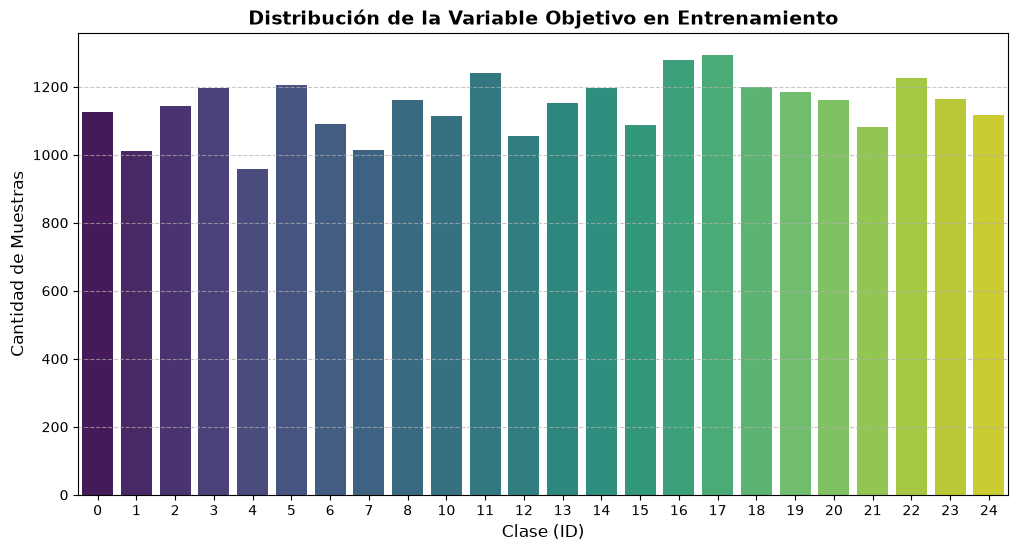

In [45]:
# COMPLETAR: calcular el número de imágenes por clase.
# COMPLETAR: representar gráficamente la distribución de clases.

print(f"Suma de valores en la columna Objetivo en entrenamiento: { y_train.value_counts()}")

df_plot = y_train.value_counts().reset_index(name="cantidad")
df_plot.columns = ["id", "cantidad"]

df_plot = df_plot.sort_values(by="id", ascending=True)

plt.figure(figsize=(12, 6))
sns.barplot(
    x="id",
    y="cantidad",
    data=df_plot,
    order=df_plot["id"],
    palette="viridis",
)

plt.title(
    "Distribución de la Variable Objetivo en Entrenamiento",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Clase (ID)", fontsize=12)
plt.ylabel("Cantidad de Muestras", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

## 3.2 Inspección visual de imágenes

[COMPLETAR: mostrar ejemplos representativos de cada clase e identificar posibles problemas de calidad, variabilidad o etiquetado.]

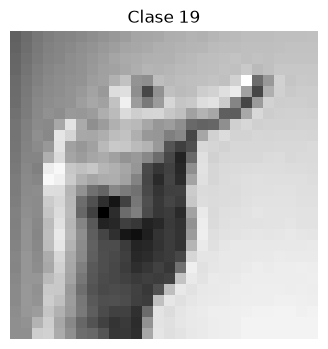

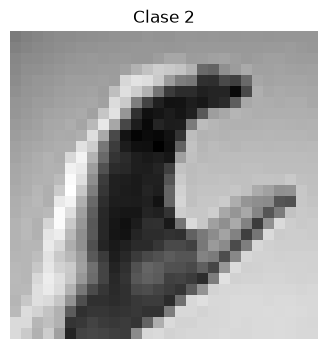

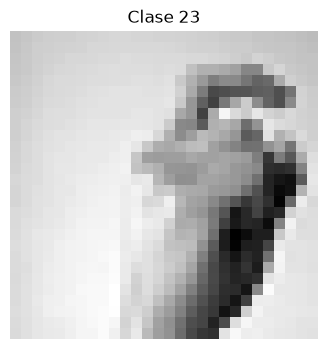

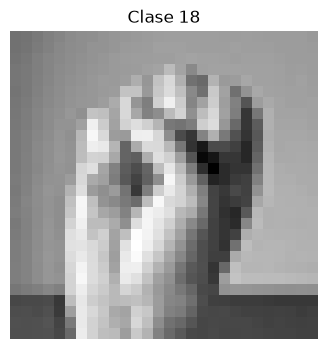

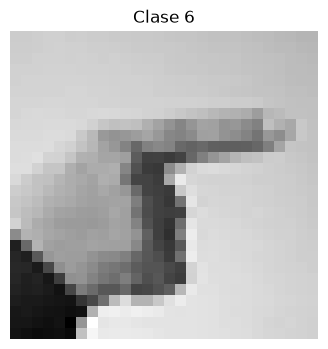

In [61]:
# COMPLETAR: visualizar una selección de imágenes con sus etiquetas.
for i in range(5):
    num = random.randint(1,100)
    fila_pixeles = X_train.iloc[num].values

    imagen_2d = fila_pixeles.reshape(28, 28)
    plt.figure(figsize=(4, 4))
    plt.imshow(
        imagen_2d, cmap="gray"
    )  
    plt.title(f"Clase {y_train.iloc[num]}")
    plt.axis("off") 
    plt.show()



## 3.3 Conclusiones del análisis exploratorio

[COMPLETAR: resumir los aspectos del dataset que condicionan el preprocesamiento y el diseño de los modelos.]

# 4. Estrategia 1 — CNN desde cero (*from scratch*)

## 4.1 Diseño de la arquitectura inicial

[COMPLETAR: justificar número de bloques convolucionales, filtros, tamaño de kernel, activaciones, pooling y capas finales.]

In [80]:
# COMPLETAR: definir la arquitectura CNN desde cero con TensorFlow/Keras.
# COMPLETAR: mostrar el resumen de la arquitectura.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras import layers

X_train_2d = X_train.values.reshape(-1, 28, 28, 1)
X_test_2d = X_test.values.reshape(-1, 28, 28, 1)
print(X_train_2d.shape)
print(X_test_2d.shape)

cnn_sign_mnist = Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(25, activation="softmax")
])

cnn_sign_mnist.summary()

(27455, 28, 28, 1)
(7172, 28, 28, 1)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,969 (886.60 KB)

 Trainable params: 226,969 (886.60 KB)

 Non-trainable params: 0 (0.00 B)

## 4.2 Configuración del entrenamiento

- Optimizador: [COMPLETAR]
- Learning rate: [COMPLETAR]
- Batch size: [COMPLETAR]
- Número de épocas: [COMPLETAR]
- Función de pérdida: [COMPLETAR]
- Métricas: [COMPLETAR]
- Callbacks (si se utilizan): [COMPLETAR]

[COMPLETAR: justificar la configuración elegida.]

In [81]:
# COMPLETAR: compilar el modelo.
# COMPLETAR: definir callbacks de monitorización/regularización si procede.
# COMPLETAR: entrenar el modelo y conservar el historial.

cnn_sign_mnist.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mnist = cnn_sign_mnist.fit(
    X_train_2d,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/5
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.7014 - loss: 2.2950 - val_accuracy: 0.9927 - val_loss: 0.0417
Epoch 2/5
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9990 - loss: 0.0114 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 3/5
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 4/5
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 7.2156e-04 - val_accuracy: 1.0000 - val_loss: 6.9240e-04
Epoch 5/5
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 4.3224e-04 - val_accuracy: 1.0000 - val_loss: 4.9809e-04


## 4.3 Monitorización del entrenamiento

[COMPLETAR: representar las curvas de pérdida y métricas de entrenamiento y validación. Interpretar convergencia, sobreajuste o subajuste.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


## 4.4 Experimentación progresiva y regularización

Realizar experimentos que permitan estudiar el efecto de las decisiones de diseño. Considerar, cuando sea pertinente:

- *Weight regularization*.
- *Dropout*.
- *Batch normalization*.
- *Data augmentation*.
- Cambios en la arquitectura, optimizador o learning rate.

**Experimento 1 — objetivo e hipótesis:** [COMPLETAR]  
**Cambios respecto al experimento anterior:** [COMPLETAR]  
**Resultados observados:** [COMPLETAR]  
**Interpretación y decisión para el siguiente experimento:** [COMPLETAR]

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.


## 4.5 Selección del modelo *from scratch*

[COMPLETAR: identificar el modelo seleccionado y justificarlo a partir de los resultados de validación y del comportamiento durante el entrenamiento.]

In [ ]:
# COMPLETAR: recuperar/cargar el modelo seleccionado para la evaluación final.


# 5. Estrategia 2 — Modelos preentrenados

Se deberán comparar **al menos dos arquitecturas CNN preentrenadas sobre ImageNet**. Para cada una, documentar *transfer learning* y *fine-tuning*, además de los experimentos realizados.

## 5.1 Decisiones comunes

- Resolución de entrada: [COMPLETAR]
- Preprocesamiento específico de cada arquitectura: [COMPLETAR]
- Pesos iniciales: [COMPLETAR]
- Estrategia para congelar/descongelar capas: [COMPLETAR]
- Clasificador final: [COMPLETAR]
- Regularización y *data augmentation*: [COMPLETAR]

[COMPLETAR: justificar las decisiones comunes y las diferencias entre arquitecturas.]

## 5.2 Arquitectura preentrenada 1 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.3 Arquitectura preentrenada 2 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.4 Comparación de arquitecturas preentrenadas

[COMPLETAR: comparar ambas arquitecturas con las mismas particiones y métricas. Analizar rendimiento, coste computacional y generalización.]

In [ ]:
# COMPLETAR: preparar una tabla comparativa con los resultados de las
# arquitecturas preentrenadas y sus variantes (transfer learning/fine-tuning).


# 6. Evaluación y comparación global de estrategias

## 6.1 Evaluación final sobre test

[COMPLETAR: evaluar únicamente los modelos seleccionados sobre el conjunto de test. No utilizar test para tomar decisiones durante el entrenamiento.]

In [ ]:
# COMPLETAR: evaluar el modelo from scratch sobre test.
# COMPLETAR: evaluar los modelos preentrenados seleccionados sobre test.
# COMPLETAR: registrar las métricas generadas durante la ejecución.


## 6.2 Métricas y análisis por clase

[COMPLETAR: incluir métricas apropiadas para el problema. Considerar matriz de confusión, precision, recall, F1-score y métricas por clase cuando proceda.]

In [ ]:
# COMPLETAR: generar matrices de confusión y métricas por clase.
# COMPLETAR: generar las visualizaciones correspondientes.


## 6.3 Comparación de resultados

Comparar, como mínimo:

- Rendimiento sobre el conjunto de test.
- Evolución del entrenamiento y validación.
- Capacidad de generalización.
- Evidencias de sobreajuste o subajuste.
- Tiempo/coste de entrenamiento, si se ha medido.
- Ventajas e inconvenientes de cada estrategia.

**Análisis:** [COMPLETAR]

In [ ]:
# COMPLETAR: construir una tabla o visualización comparativa final
# con métricas obtenidas durante la ejecución.


## 6.4 Errores y ejemplos de predicción

[COMPLETAR: inspeccionar ejemplos correctamente e incorrectamente clasificados. Analizar patrones de error y posibles causas.]

In [ ]:
# COMPLETAR: visualizar ejemplos de predicciones y errores del modelo.


# 7. Conclusiones

## 7.1 Mejor modelo y estrategia

[COMPLETAR: indicar qué modelo ofrece la mejor solución y justificar la elección con resultados de test y evidencias experimentales.]

## 7.2 Aprendizajes y análisis crítico

[COMPLETAR: explicar qué decisiones tuvieron mayor impacto, qué técnicas ayudaron o no y qué limitaciones se encontraron.]

## 7.3 Posibles mejoras futuras

[COMPLETAR]

# 8. Referencias

[COMPLETAR: incluir referencias al dataset, documentación de TensorFlow/Keras, artículos y recursos utilizados.]

# 9. Lista de comprobación y exportación a PDF

Antes de entregar:

- [ ] Todas las secciones están completadas.
- [ ] El código se ha ejecutado y no quedan errores.
- [ ] Se muestran evidencias de entrenamiento real para todos los modelos presentados.
- [ ] Las métricas y figuras proceden de la ejecución del notebook.
- [ ] El conjunto de test se ha reservado para la evaluación final.
- [ ] Las conclusiones están respaldadas por los experimentos.
- [ ] El PDF incluye explicaciones, código ejecutado, resultados y figuras.

**Exportación:** generar el PDF directamente desde el notebook de Colab, de modo que se incluyan las celdas y sus salidas. La conversión mediante `nbconvert` puede requerir dependencias LaTeX adicionales.

In [ ]:
# COMPLETAR: si se desea automatizar la exportación a PDF desde Colab,
# configurar aquí las rutas y comandos necesarios.
